## Загрузка данных и вывод статистик

In [ ]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from phik.report import plot_correlation_matrix
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OrdinalEncoder,
    TargetEncoder,
)
from xgboost import XGBRegressor

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
%matplotlib inline

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv('all_v2.csv')

In [3]:
df.head()

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1


In [4]:
df.describe()

,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
count,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06,5.477006e+06
mean,4.422029e+06,5.403826e+01,5.324433e+01,4.307141e+03,1.948966e+00,6.214530e+00,1.139892e+01,1.726173e+00,5.391825e+01,1.062840e+01,3.945399e+00
std,2.150752e+07,4.622758e+00,2.074763e+01,3.308050e+03,1.038537e+00,4.957419e+00,6.535734e+00,1.082133e+00,3.335293e+01,9.792380e+00,4.558357e+00
min,-2.144967e+09,4.145906e+01,1.989020e+01,3.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,-2.000000e+00,7.000000e-02,1.000000e-02,1.000000e+00
25%,1.950000e+06,5.337768e+01,3.777790e+01,2.661000e+03,1.000000e+00,2.000000e+00,5.000000e+00,1.000000e+00,3.800000e+01,7.000000e+00,1.000000e+00
50%,2.990000e+06,5.517139e+01,4.306774e+01,2.922000e+03,2.000000e+00,5.000000e+00,1.000000e+01,2.000000e+00,4.802000e+01,9.700000e+00,1.000000e+00
75%,4.802000e+06,5.622613e+01,6.564895e+01,6.171000e+03,3.000000e+00,9.000000e+00,1.600000e+01,2.000000e+00,6.313000e+01,1.270000e+01,1.100000e+01
max,2.147484e+09,7.198040e+01,1.625361e+02,6.188800e+04,5.000000e+00,3.900000e+01,3.900000e+01,1.000000e+01,7.856000e+03,9.999000e+03,1.100000e+01


In [5]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5477006 entries, 0 to 5477005
Data columns (total 13 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   price          5477006 non-null  int64  
 1   date           5477006 non-null  str    
 2   time           5477006 non-null  str    
 3   geo_lat        5477006 non-null  float64
 4   geo_lon        5477006 non-null  float64
 5   region         5477006 non-null  int64  
 6   building_type  5477006 non-null  int64  
 7   level          5477006 non-null  int64  
 8   levels         5477006 non-null  int64  
 9   rooms          5477006 non-null  int64  
 10  area           5477006 non-null  float64
 11  kitchen_area   5477006 non-null  float64
 12  object_type    5477006 non-null  int64  
dtypes: float64(4), int64(7), str(2)
memory usage: 543.2 MB


**Выводы:**
- Нет пропусков
- 'time' не несет в себе никакой полезной для нас информации

In [6]:
df = df.drop(columns=['time'])

In [7]:
df.nunique()

price            352726
date               1075
geo_lat          448318
geo_lon          449701
region               84
building_type         6
level                39
levels               39
rooms                12
area              12741
kitchen_area       4154
object_type           2
dtype: int64

## Построение графиков для каждой фичи

In [8]:
def sns_plot(df: pd.DataFrame, feature: str, bins=-1, color='#3498db'):
    if bins == -1:
        bins = df[feature].nunique()
    
    plt.figure(figsize=(10,5))
    
    # Описательная статистика
    display(df[feature].describe())
    
    sns.histplot(data=df, x=feature, bins=bins, color=color, edgecolor="black")
    
    plt.title(f"Распределение признака '{feature}'", fontsize=16)
    plt.xlabel(feature, fontsize=12)
    plt.ylabel("Количество", fontsize=12)
    plt.show()


### Целочисленные признаки

In [9]:
int_features = df.select_dtypes(include='int64')
int_features

,price,region,building_type,level,levels,rooms,object_type
0,6050000,2661,1,8,10,3,1
1,8650000,81,3,5,24,2,1
2,4000000,2871,1,5,9,3,1
3,1850000,2843,4,12,16,2,11
4,5450000,81,3,13,14,2,1
...,...,...,...,...,...,...,...
5477001,19739760,3,1,8,17,4,11
5477002,12503160,3,2,17,32,2,11
5477003,8800000,2871,2,4,17,3,1
5477004,11831910,3,1,8,33,2,11


count    5.477006e+06
mean     4.422029e+06
std      2.150752e+07
min     -2.144967e+09
25%      1.950000e+06
50%      2.990000e+06
75%      4.802000e+06
max      2.147484e+09
Name: price, dtype: float64

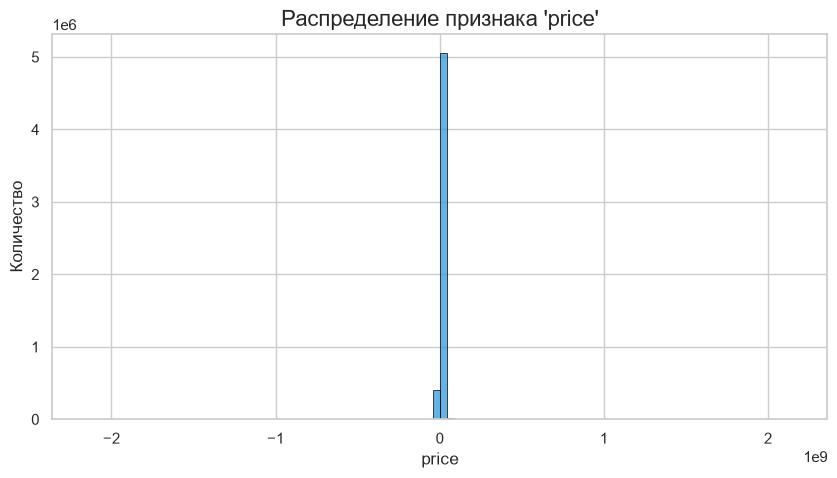

In [10]:
sns_plot(int_features, int_features.columns[0], bins=100)

**Выводы:** Убрать выбросы, как сверху, так и снизу.

count    5.477006e+06
mean     4.307141e+03
std      3.308050e+03
min      3.000000e+00
25%      2.661000e+03
50%      2.922000e+03
75%      6.171000e+03
max      6.188800e+04
Name: region, dtype: float64

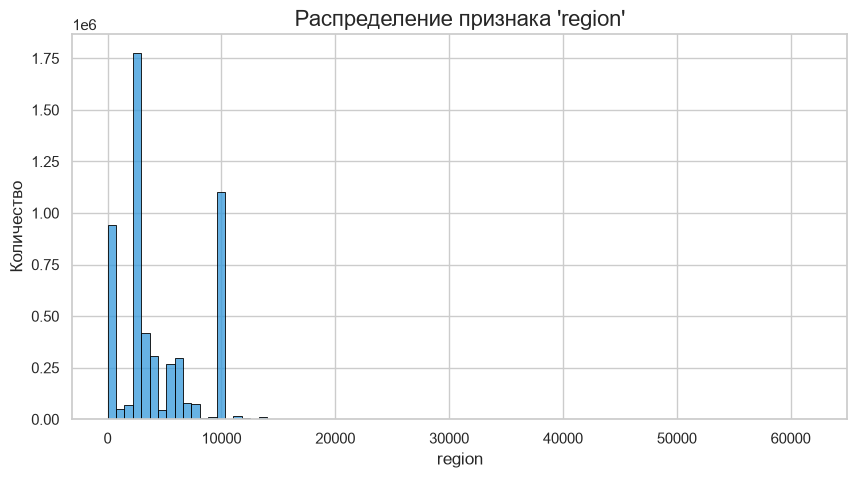

In [11]:
sns_plot(int_features, int_features.columns[1])

**Выводы:** Категориальная переменная  

count    5.477006e+06
mean     1.948966e+00
std      1.038537e+00
min      0.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      5.000000e+00
Name: building_type, dtype: float64

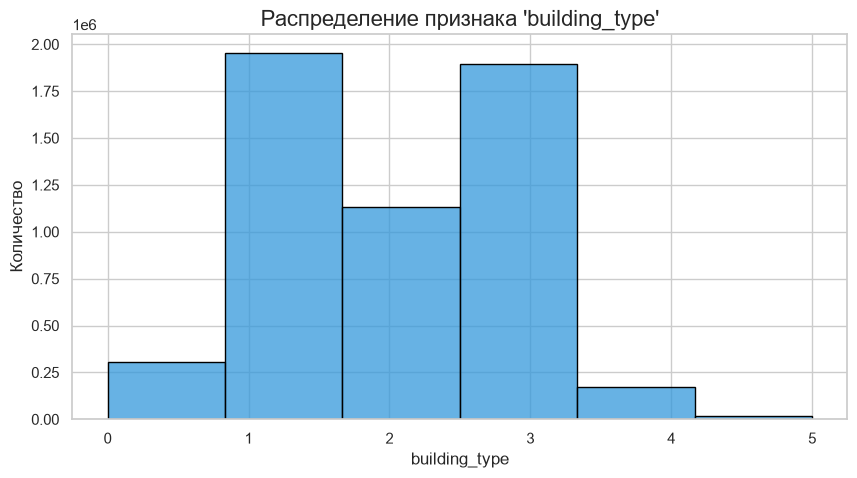

In [12]:
sns_plot(int_features, int_features.columns[2])

In [13]:
int_features['building_type'].value_counts()

building_type
1    1955661
3    1892756
2    1130731
0     307165
4     174356
5      16337
Name: count, dtype: int64

**Выводы:** Категориальная переменная  

count    5.477006e+06
mean     6.214530e+00
std      4.957419e+00
min      1.000000e+00
25%      2.000000e+00
50%      5.000000e+00
75%      9.000000e+00
max      3.900000e+01
Name: level, dtype: float64

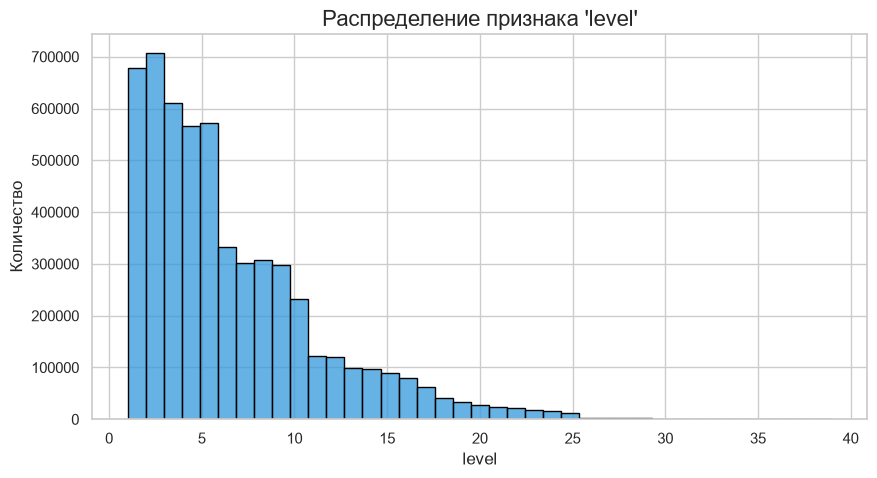

In [14]:
sns_plot(int_features, int_features.columns[3])

count    5.477006e+06
mean     1.139892e+01
std      6.535734e+00
min      1.000000e+00
25%      5.000000e+00
50%      1.000000e+01
75%      1.600000e+01
max      3.900000e+01
Name: levels, dtype: float64

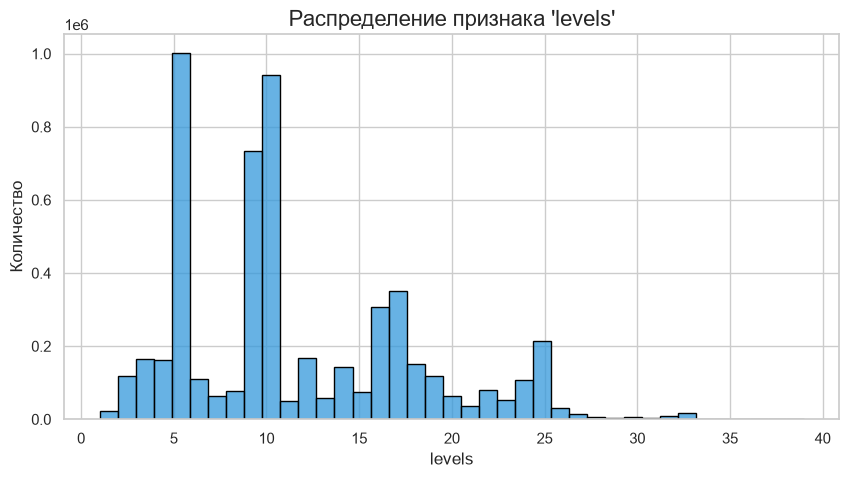

In [15]:
sns_plot(int_features, int_features.columns[4])

count    5.477006e+06
mean     1.726173e+00
std      1.082133e+00
min     -2.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      1.000000e+01
Name: rooms, dtype: float64

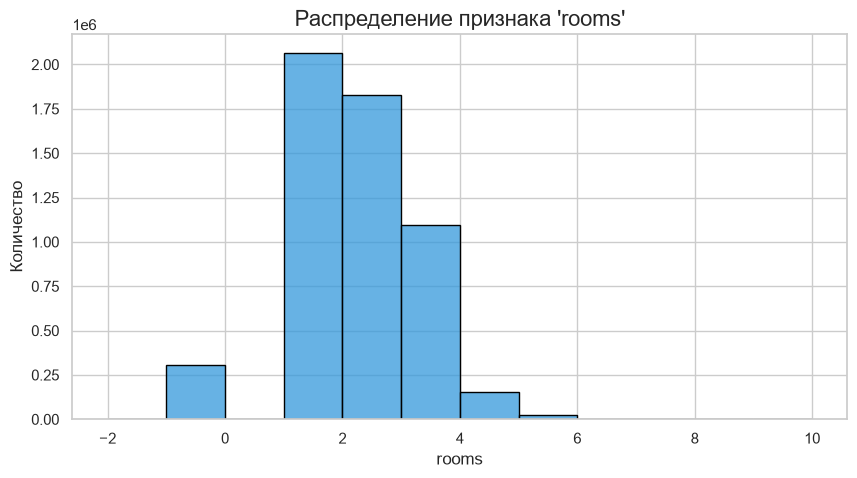

In [16]:
sns_plot(int_features, int_features.columns[5])

In [17]:
int_features['rooms'].value_counts()

rooms
 1     2067013
 2     1827514
 3     1097354
-1      306209
 4      152160
 5       22576
 6        2357
 7         788
 8         353
-2         343
 9         338
 10          1
Name: count, dtype: int64

**Выводы:** Изменить значение с -1 на 0. Удалить выбросы

count    5.477006e+06
mean     3.945399e+00
std      4.558357e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.100000e+01
max      1.100000e+01
Name: object_type, dtype: float64

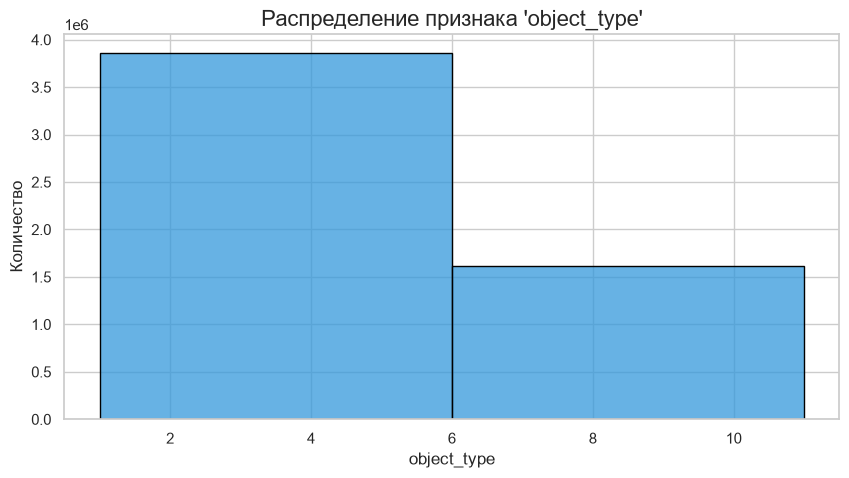

In [18]:
sns_plot(int_features, int_features.columns[6])

In [19]:
df['object_type'].unique()

array([ 1, 11])

**Выводы:** Привести к 0 и 1

### Признаки типа float

In [20]:
float_features = df.select_dtypes(include='float64')
float_features

,geo_lat,geo_lon,area,kitchen_area
0,59.805808,30.376141,82.6,10.8
1,55.683807,37.297405,69.1,12.0
2,56.295250,44.061637,66.0,10.0
3,44.996132,39.074783,38.0,5.0
4,55.918767,37.984642,60.0,10.0
...,...,...,...,...
5477001,55.804736,37.750898,93.2,13.8
5477002,55.841415,37.489624,45.9,6.6
5477003,56.283909,44.075408,86.5,11.8
5477004,55.804736,37.750898,52.1,18.9


count    5.477006e+06
mean     5.403826e+01
std      4.622758e+00
min      4.145906e+01
25%      5.337768e+01
50%      5.517139e+01
75%      5.622613e+01
max      7.198040e+01
Name: geo_lat, dtype: float64

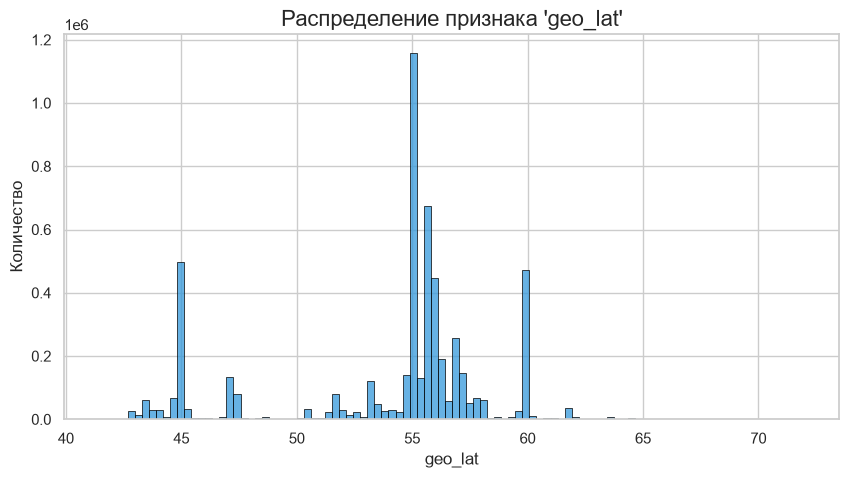

In [21]:
sns_plot(float_features, float_features.columns[0], bins=100)

count    5.477006e+06
mean     5.324433e+01
std      2.074763e+01
min      1.989020e+01
25%      3.777790e+01
50%      4.306774e+01
75%      6.564895e+01
max      1.625361e+02
Name: geo_lon, dtype: float64

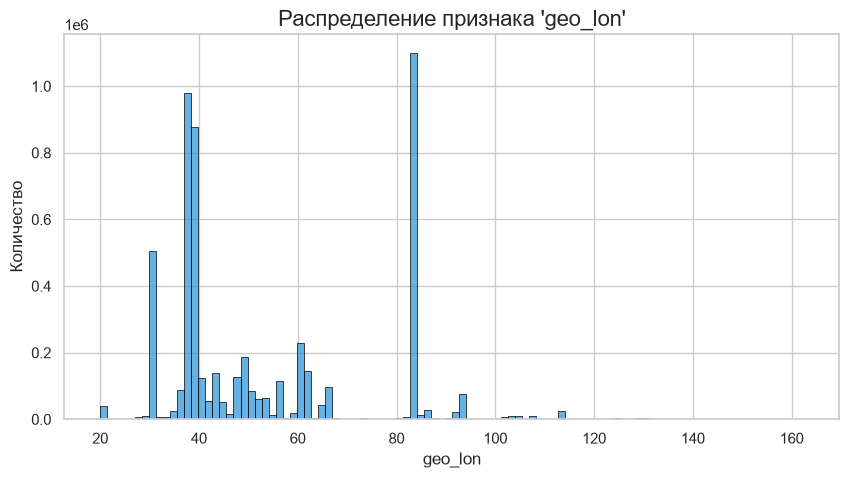

In [22]:
sns_plot(float_features, float_features.columns[1], bins=100)

count    5.477006e+06
mean     5.391825e+01
std      3.335293e+01
min      7.000000e-02
25%      3.800000e+01
50%      4.802000e+01
75%      6.313000e+01
max      7.856000e+03
Name: area, dtype: float64

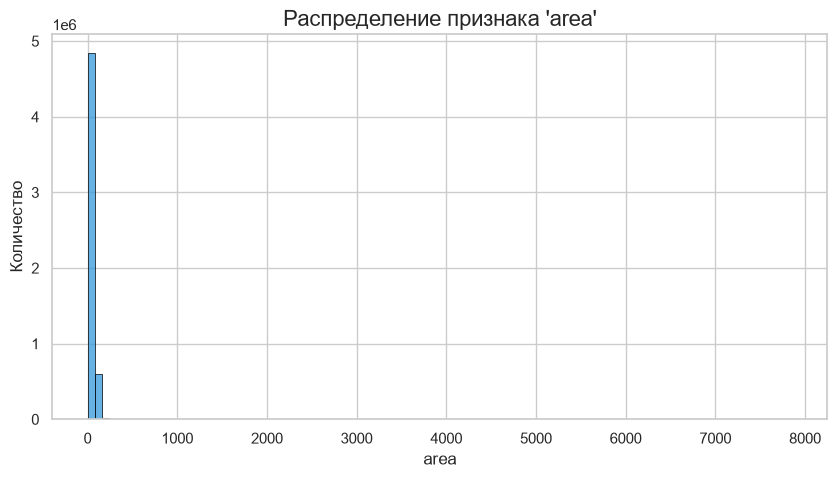

In [23]:
sns_plot(float_features, float_features.columns[2], bins=100)

In [24]:
float_features["area"].sort_values(ascending=False).head(10)

3418563    7856.0
3043425    7660.0
3608366    7625.0
5342906    7513.4
3418858    7190.0
5153758    6812.6
1845359    6580.0
3463169    5985.0
3650748    5711.6
1766037    5644.0
Name: area, dtype: float64

**Выводы:** убираем выбросы c двух сторон

count    5.477006e+06
mean     1.062840e+01
std      9.792380e+00
min      1.000000e-02
25%      7.000000e+00
50%      9.700000e+00
75%      1.270000e+01
max      9.999000e+03
Name: kitchen_area, dtype: float64

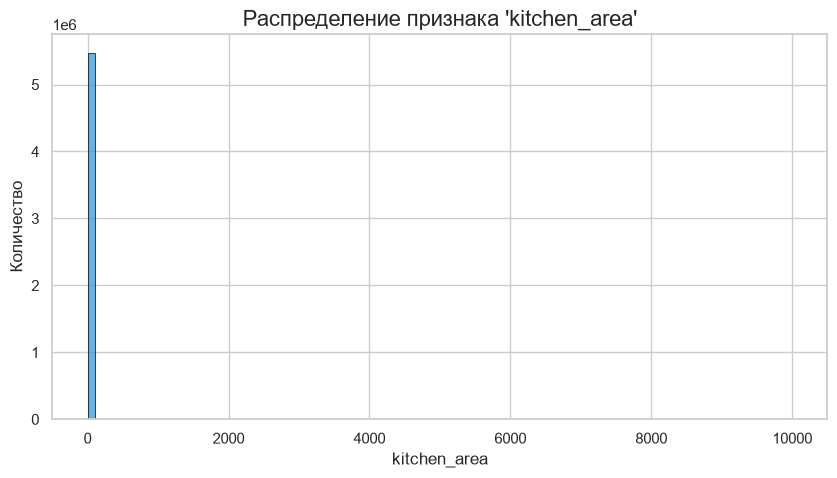

In [25]:
sns_plot(float_features, float_features.columns[3], bins=100)

In [26]:
float_features["kitchen_area"].sort_values(ascending=False).head(10)

1042411    9999.0
3189364    8235.0
1583599    6500.0
3656328    6270.0
1766037    4949.0
1756576    3000.0
3701466    3000.0
836659     2500.0
1268810    2110.0
251807     1958.0
Name: kitchen_area, dtype: float64

**Выводы:** убираем выбросы

### Категориальные признаки

In [27]:
cat_features = df.select_dtypes(include='object')
cat_features

D:\Temp\ipykernel_20648\2326374793.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df.select_dtypes(include='object')


,date
0,2018-02-19
1,2018-02-27
2,2018-02-28
3,2018-03-01
4,2018-03-01
...,...
5477001,2021-05-01
5477002,2021-05-01
5477003,2021-05-01
5477004,2021-05-01


count        5477006
unique          1075
top       2020-03-27
freq           44764
Name: date, dtype: object

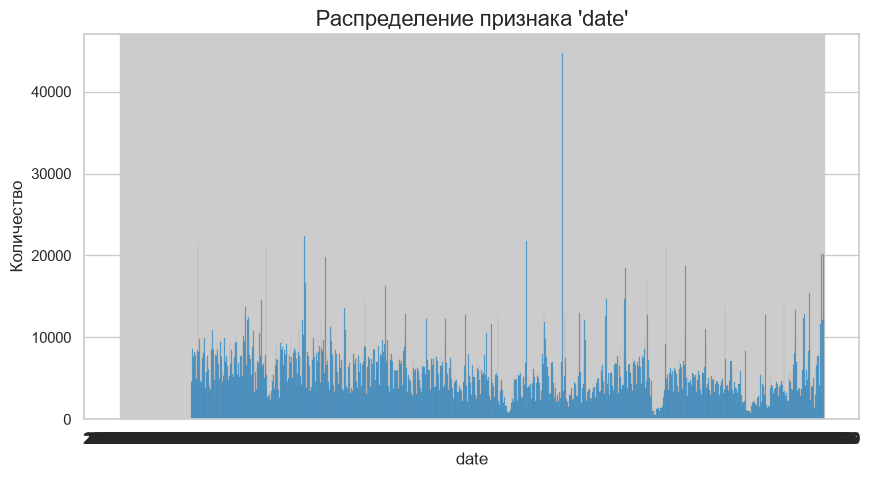

In [28]:
sns_plot(cat_features, cat_features.columns[0], bins=100)

**Выводы:** требуется преобразовать в категориальную переменную

## Очистка данных

### Изменяем тип

In [29]:
df['region'] = df['region'].astype('object')
df['building_type'] = df['building_type'].astype('object')
df['object_type'] = df['object_type'].map({1: 0, 11: 1})

### Убираем дубликаты

In [30]:
cols = df.columns.drop('date')
is_duplicated = df.duplicated(subset=cols ,keep='first')
print(sum(is_duplicated))

1071288


In [31]:
df[is_duplicated].sort_values(by=list(df.columns))

,price,date,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
4427261,-2144967296,2020-09-22,54.940556,82.883895,9654,1,1,10,1,33.60,9.0,0
3829586,-2114967296,2020-06-02,54.935003,82.907332,9654,3,2,5,2,43.40,6.0,0
1108531,-2114150296,2019-02-09,55.017672,83.003522,9654,1,8,10,3,87.39,13.0,1
1114226,-2114150296,2019-02-10,55.017672,83.003522,9654,1,8,10,3,87.39,13.0,1
1119183,-2114150296,2019-02-11,55.017672,83.003522,9654,1,8,10,3,87.39,13.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1634279,2083290000,2019-04-18,54.947786,82.970996,9654,4,9,10,2,63.00,12.0,0
1640981,2083290000,2019-04-19,54.947786,82.970996,9654,4,9,10,2,63.00,12.0,0
1645744,2083290000,2019-04-20,54.947786,82.970996,9654,4,9,10,2,63.00,12.0,0
1650146,2083290000,2019-04-21,54.947786,82.970996,9654,4,9,10,2,63.00,12.0,0


**Выводы:** Нашли 1М дубликатов, удаляем их

In [32]:
df = df[~is_duplicated].reset_index(drop=True)

### Удаляем выбросы

In [33]:
df.loc[df['rooms'] == -1, 'rooms'] = 0
df = df[df['rooms'] != -2]
df = df[df['rooms'] <= 5].reset_index(drop=True)

In [ ]:
cols = ['price', 'area', 'kitchen_area']

outliers = pd.DataFrame()

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 3 * IQR
    
    if col == 'price':
        lower = 500000
    elif col == 'area':
        lower = 10
    else: 
        lower = 1
        
    outliers[col] = ~df[col].between(lower, upper)
    
outliers = outliers.any(axis=1)

df[~outliers][cols].describe()

,price,area,kitchen_area
count,4.177531e+06,4.177531e+06,4.177531e+06
mean,3.871053e+06,5.099908e+01,1.018450e+01
std,2.546322e+06,1.849906e+01,4.268647e+00
min,5.000000e+05,1.000000e+01,1.000000e+00
25%,2.100000e+06,3.760000e+01,7.000000e+00
50%,3.100000e+06,4.670000e+01,9.300000e+00
75%,4.849000e+06,6.140000e+01,1.200000e+01
max,1.435000e+07,1.380000e+02,2.900000e+01


In [35]:
print (outliers.sum() / len(df))

0.0509120831910564


In [36]:
df = df[~outliers].reset_index(drop=True)

**Выводы:** Удалили 5% выбросов, что является приемлемой платой за повышение устойчивости модели.

### Удаляем аномалии

In [37]:
t = df[df['level'] > df['levels']]
print(f"Этаж выше общего количества этажей: {len(t)}")

t = df[df['kitchen_area'] > df['area']]
print(f"Кухня больше общей площади: {len(t)}")

Этаж выше общего количества этажей: 343
Кухня больше общей площади: 30


In [38]:
df = df[df['level'] <= df['levels']]
df = df[df['kitchen_area'] <= df['area']]

Перезапустил графики. Все выглядит намного лучше.

## Feature Engineering

Новые признаки c датой

In [39]:
df['date'] = pd.to_datetime(df['date'])

df['days_passed'] = (df['date'] - df['date'].min()).dt.days

# Добавим среднюю ставку по ипотеке со сдвигом на 1 месяц
mortgage_dict = {(2018, 1): 9.85, (2018, 2): 9.75, (2018, 3): 9.64, (2018, 4): 9.57, (2018, 5): 9.56, 
                 (2018, 6): 9.48, (2018, 7): 9.57, (2018, 8): 9.42, (2018, 9): 9.41, (2018, 10): 9.41, 
                 (2018, 11): 9.52, (2018, 12): 9.66, (2019, 1): 9.87, (2019, 2): 10.15, (2019, 3): 10.42,
                 (2019, 4): 10.56, (2019, 5): 10.53, (2019, 6): 10.28, (2019, 7): 10.24, (2019, 8): 9.91,
                 (2019, 9): 9.68, (2019, 10): 9.40, (2019, 11): 9.19, (2019, 12): 9.00, (2020, 1): 8.89, 
                 (2020, 2): 8.85, (2020, 3): 8.62, (2020, 4): 8.32, (2020, 5): 7.40, (2020, 6): 7.28, 
                 (2020, 7): 7.14, (2020, 8): 7.16, (2020, 9): 7.32, (2020, 10): 7.31, (2020, 11): 7.38, 
                 (2020, 12): 7.36, (2021, 1): 7.23, (2021, 2): 7.26, (2021, 3): 7.23, (2021, 4): 7.30, (2021, 5): 7.30}

df['mortgage_rate'] = (df['date'].dt.to_period('M') - 1).apply(lambda r: mortgage_dict.get((r.year, r.month)))

# Добавим средний кус доллара со сдвигом на 1 месяц
usd_dict = {(2018, 1): 56.7, (2018, 2): 56.8, (2018, 3): 57.0, (2018, 4): 60.5, (2018, 5): 62.2, (2018, 6): 62.7, 
            (2018, 7): 62.9, (2018, 8): 66.1, (2018, 9): 67.7, (2018, 10): 65.8, (2018, 11): 66.2, (2018, 12): 67.3, 
            (2019, 1): 66.5, (2019, 2): 65.8, (2019, 3): 65.1, (2019, 4): 64.6, (2019, 5): 64.8, (2019, 6): 64.2,
            (2019, 7): 63.0, (2019, 8): 65.6, (2019, 9): 65.0, (2019, 10): 64.3, (2019, 11): 63.9, (2019, 12): 62.9,
            (2020, 1): 61.8, (2020, 2): 63.9, (2020, 3): 73.7, (2020, 4): 75.2, (2020, 5): 72.6, (2020, 6): 69.2,
            (2020, 7): 71.3, (2020, 8): 73.8, (2020, 9): 75.7, (2020, 10): 77.6, (2020, 11): 77.0, (2020, 12): 74.1,
            (2021, 1): 74.4, (2021, 2): 74.4, (2021, 3): 74.4, (2021, 4): 76.0, (2021, 5): 74.0}

df['usd_rate'] = (df['date'].dt.to_period('M') - 1).apply(lambda r: usd_dict.get((r.year, r.month)))

In [40]:
df = df.drop(columns='date')

Квартиры на последнем этаже обычно дороже

In [41]:
df['relative_level'] = df['level'] / df['levels']    

df['is_last_level'] = (df['levels'] == df['level']).astype(int)

Добавим расстояние от центра для каждого региона

In [42]:
df['geo_lat_cntr'] = df.groupby('region')['geo_lat'].transform('median')
df['geo_lon_cntr'] = df.groupby('region')['geo_lon'].transform('median')

# Гаверсинус для расстояинй
def get_dist(lat1, lon1, lat2, lon2):
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distance'] = get_dist(df['geo_lat'], df['geo_lon'], df['geo_lat_cntr'], df['geo_lon_cntr'])
df = df.drop(columns=['geo_lat_cntr', 'geo_lon_cntr'])

## Матрица корреляции

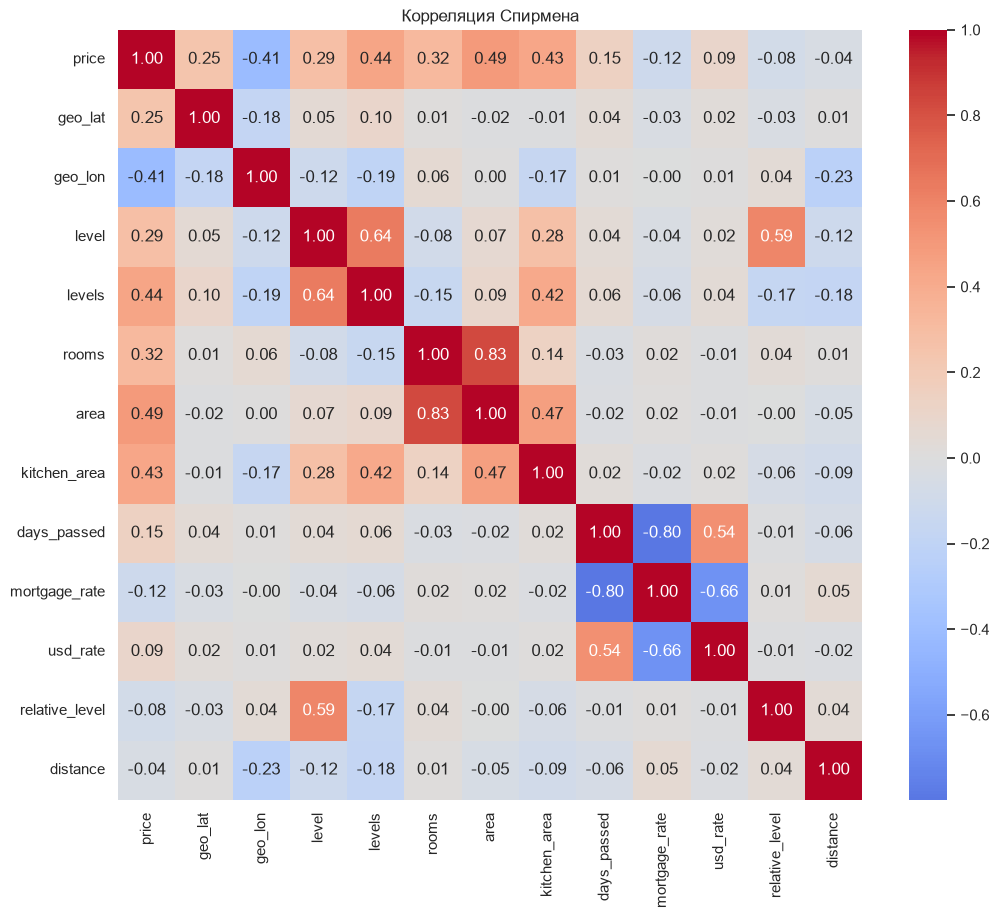

In [43]:
object_cols = ['region', 'building_type', 'object_type', 'is_last_level']
num_cols = df.drop(columns=object_cols).columns.tolist()

plt.figure(figsize=(12, 10))
sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title('Корреляция Спирмена')
plt.show()

**Выводы**
* Между ценой на квартиру, площадью квартиры и количеством этажей самая большая корреляция.
* 'area', 'rooms' и 'kitchen_area' - мультиколлинеарные признаки.
* 'days_passed', 'mortgage_rate', 'usd_rate' - мультиколлинеарные признаки.
* 'level' и 'levels' - мультиколлинеарные признаки.
* 'distance' и 'relative_level' имеют слишком низкую корреляцию с целевой переменной

Для категориальных признаков рассмотрим матрицу корреляций $\phi_k$

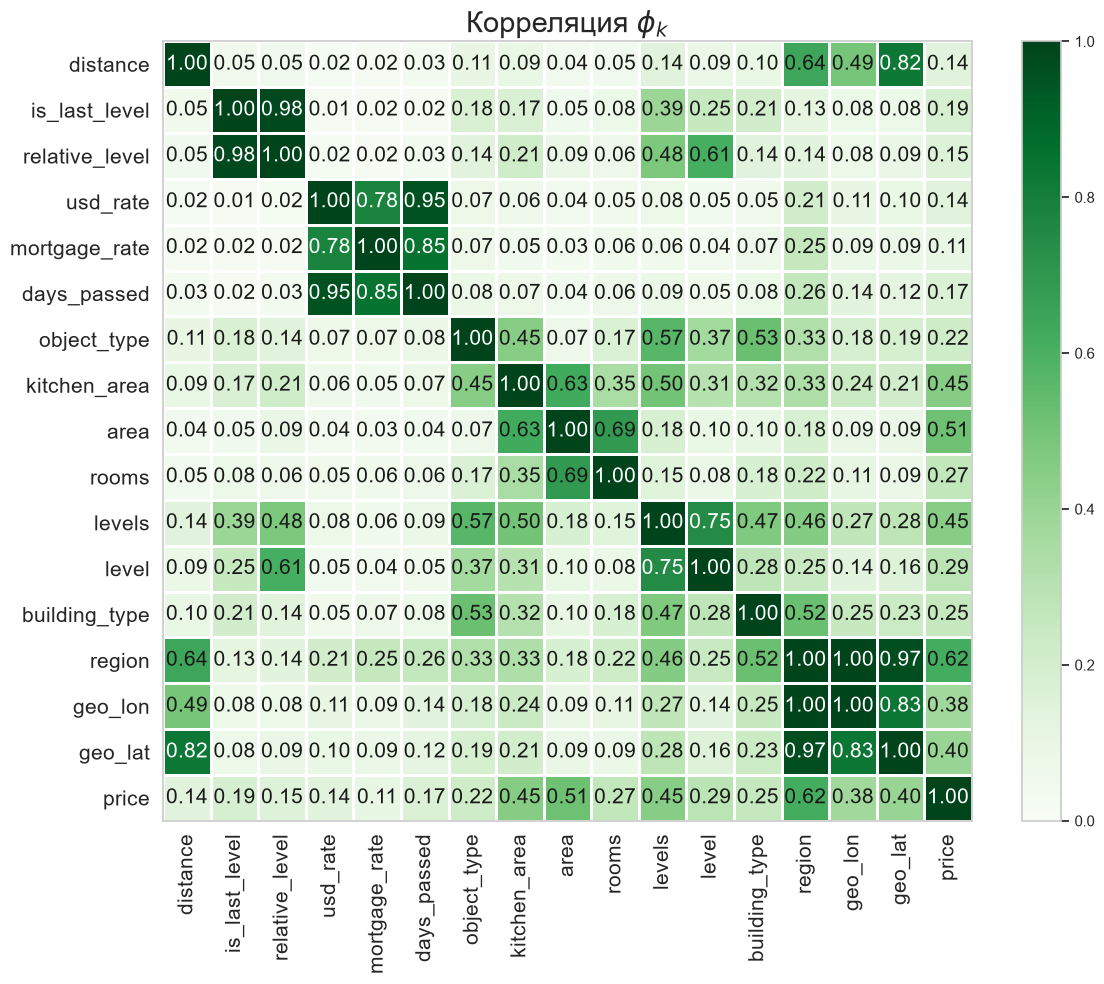

In [44]:
phik_matrix = df.phik_matrix(interval_cols=num_cols)

plot_correlation_matrix(phik_matrix.values, 
                        x_labels=phik_matrix.columns, 
                        y_labels=phik_matrix.index, 
                        vmin=0, vmax=1, color_map="Greens", 
                        title=r"Корреляция $\phi_k$", 
                        fontsize_factor=1.5, figsize=(12, 10))
plt.show()

## Еще графики

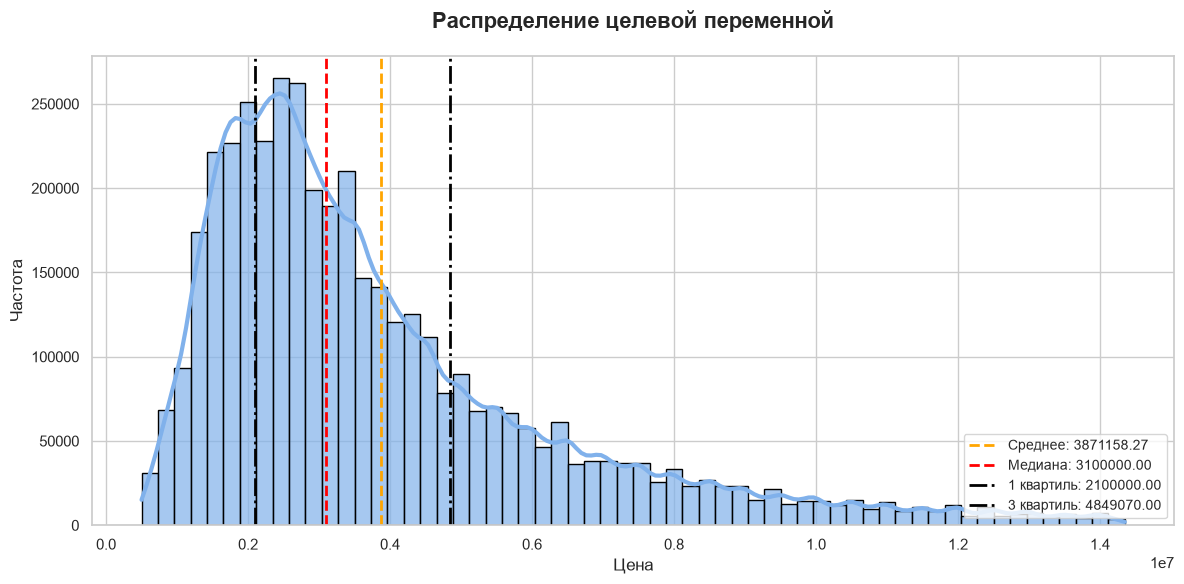

In [45]:
target = df["price"]

mean_val = target.mean()
median_val = target.median()
q1 = target.quantile(0.25)
q3 = target.quantile(0.75)
std_val = target.std()

plt.figure(figsize=(12, 6))
sns.histplot(target, bins=60, kde=True, color="#80B1EB", edgecolor="black", alpha=0.7, line_kws={"linewidth": 3})

plt.axvline(target.mean(), color="orange", linestyle="--", linewidth=2, label=f"Среднее: {mean_val:.2f}")
plt.axvline(target.median(), color="red", linestyle="--", linewidth=2, label=f"Медиана: {median_val:.2f}")
plt.axvline(target.quantile(0.25), color="black", linestyle="-.", linewidth=2, label=f"1 квартиль: {q1:.2f}")
plt.axvline(q3, color="black", linestyle="-.", linewidth=2, label=f"3 квартиль: {q3:.2f}")

plt.title("Распределение целевой переменной", fontsize=16, weight="bold", pad=20)
plt.xlabel("Цена", fontsize=12)
plt.ylabel("Частота", fontsize=12)

plt.legend(frameon=True, fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()

**Выводы:** На линейной регрессии целевую переменную логарифмируем.

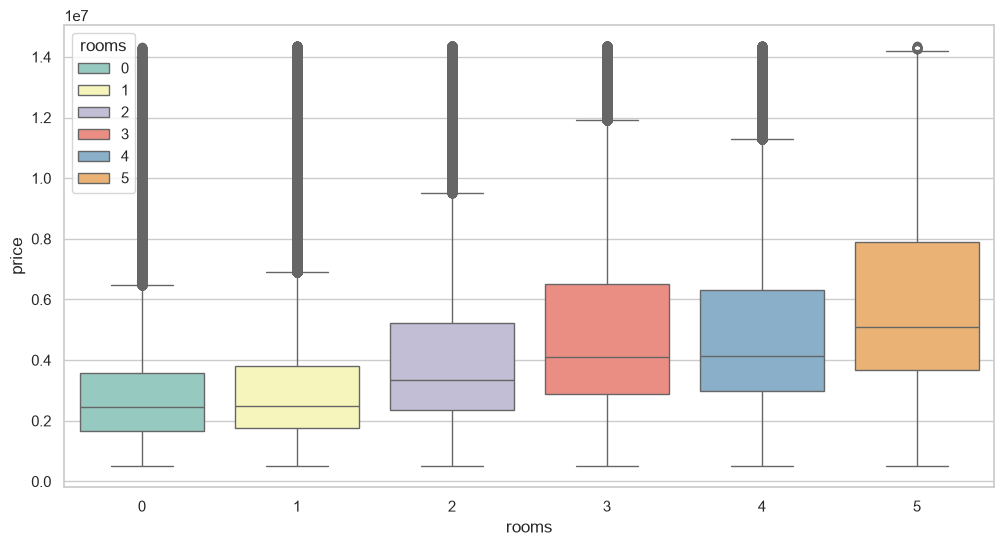

In [46]:
feature = df['rooms']

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(x=feature, y=target, ax=ax, palette="Set3", hue=feature)
ax.set_xlabel(feature.name)
ax.set_ylabel(target.name)
plt.show()

# Обучаем модели 

In [47]:
random_state = 17

In [48]:
def regression_report(y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    mean_price = y_test.mean()
    
    print(f"MAE:                {mae:,.0f} руб.  ({mae/mean_price:.1%} от средней цены)")
    print(f"RMSE:               {rmse:,.0f} руб.  ({rmse/mean_price:.1%} от средней цены)")
    print(f"R² Score:           {r2:.2%}") 
    
    print(f"Средняя цена:       {mean_price:,.0f} руб.")

## Предобратботка данных

In [49]:
X = df.drop(columns='price', errors='ignore')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)

In [50]:
def preprocess_data(X_train, X_test, y_train):
    categorical_cols = ["region", "building_type"]

    other_cols = [col for col in X_train.columns if col not in categorical_cols]

    preprocessor = ColumnTransformer(
        transformers=[
            ("region_encoding", TargetEncoder(target_type="continuous",random_state=17,),
             ["region"],),
            ("building_encoding", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,),
             ["building_type"],),
            ("other", "passthrough", other_cols),
        ],
        verbose_feature_names_out=False,).set_output(transform="pandas")

    X_train_processed = preprocessor.fit_transform(X_train, y_train)
    X_test_processed = preprocessor.transform(X_test)

    return X_train_processed, X_test_processed, preprocessor

## XGBoost

In [51]:
X_train_xgb, X_test_xgb, preprocessor = preprocess_data(X_train, X_test, y_train)

In [52]:
xgboost = XGBRegressor(n_estimators=400, n_jobs=-1, random_state=random_state, verbosity=1)

param_dist = {
    'learning_rate': [0.05, 0.07, 0.09],
    'max_depth': [8, 10, 12],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

random_search = RandomizedSearchCV(xgboost, 
    param_dist, 
    n_iter=20, 
    cv=3, 
    scoring='neg_mean_absolute_error', 
    n_jobs=-1, 
    random_state=random_state
)

random_search.fit(X_train_xgb, y_train)

RandomizedSearchCV(cv=3,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=False,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraint...
                                          max_leaves=None,
                                          min_child_weight=None, missing=nan,
                                          monotone_constraints=None,
                                          multi_strategy=None, n_estimators=400,
                                          n_jobs=-1, num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9],
                                        'learning_rate': [0.05, 0.07, 0.09],
                                        'max_depth': [8, 10, 12],
                                        'subsample': [0.7, 0.8, 0.9]},
                   random_state=17, scoring='neg_mean_absolute_error')

In [53]:
best_params = random_search.best_params_
best_params

{'subsample': 0.9,
 'max_depth': 12,
 'learning_rate': 0.09,
 'colsample_bytree': 0.8}

In [54]:
dtrain = xgb.DMatrix(X_train_xgb, label=y_train)

cv_results = xgb.cv(
    {**best_params, 'objective': 'reg:squarederror', 'eval_metric': 'mae'}, 
    dtrain,
    num_boost_round=1500,
    nfold=5,
    early_stopping_rounds=50,
    seed=random_state,
    verbose_eval=150,
    as_pandas=True
)

[0]	train-mae:1762119.03347+440.03050	test-mae:1765507.61541+5064.78140
[150]	train-mae:392501.59231+777.15666	test-mae:440878.39584+21774.48974
[300]	train-mae:355133.21857+429.99103	test-mae:421938.46671+21693.12027
[450]	train-mae:329192.61332+356.56220	test-mae:411895.76225+22157.26136
[600]	train-mae:308609.45512+336.87728	test-mae:405947.20413+22222.50043
[750]	train-mae:290616.66792+186.18206	test-mae:401514.76624+22367.37098
[900]	train-mae:274919.66532+295.51082	test-mae:398244.28252+22755.92183
[1050]	train-mae:260766.47354+258.15386	test-mae:395720.31894+22765.29196
[1200]	train-mae:247846.24650+251.60539	test-mae:393677.99409+23039.85455
[1350]	train-mae:235873.84876+349.36106	test-mae:391911.16057+23043.81400
[1499]	train-mae:224823.92077+339.02440	test-mae:390325.79401+23094.54325


In [55]:
for i in range(0, len(cv_results), 150):
    prev_test = cv_results['test-mae-mean'].iloc[i-100]
    curr_test = cv_results['test-mae-mean'].iloc[i]
    improvement = (prev_test - curr_test) / prev_test * 100
    
    train_mae = cv_results['train-mae-mean'].iloc[i]
    test_mae = cv_results['test-mae-mean'].iloc[i]
    gap = (train_mae - test_mae) / test_mae * 100
    
    print(f"Итерация {i}: улучшение={improvement:.1f}%, разница={gap:.1f}%")

Итерация 0: улучшение=-351.2%, разница=-0.2%
Итерация 150: улучшение=8.4%, разница=-11.0%
Итерация 300: улучшение=2.4%, разница=-15.8%
Итерация 450: улучшение=1.4%, разница=-20.1%
Итерация 600: улучшение=0.9%, разница=-24.0%
Итерация 750: улучшение=0.7%, разница=-27.6%
Итерация 900: улучшение=0.5%, разница=-31.0%
Итерация 1050: улучшение=0.4%, разница=-34.1%
Итерация 1200: улучшение=0.3%, разница=-37.0%
Итерация 1350: улучшение=0.3%, разница=-39.8%


Возьмем 900 итераций, оптимально чтобы не переобучиться

In [56]:
xgb_final = XGBRegressor(
    n_estimators=900,
    **best_params,
    n_jobs=-1,
    random_state=random_state
)
xgb_final.fit(X_train_xgb, y_train)

y_pred_xgb = xgb_final.predict(X_test_xgb)

regression_report(y_test, y_pred_xgb)

MAE:                379,946 руб.  (9.8% от средней цены)
RMSE:               639,640 руб.  (16.5% от средней цены)
R² Score:           93.71%
Средняя цена:       3,875,283 руб.


In [61]:
y_train_pred_xgb = xgb_final.predict(X_train_xgb)

regression_report(y_train, y_train_pred_xgb)

MAE:                286,157 руб.  (7.4% от средней цены)
RMSE:               431,236 руб.  (11.1% от средней цены)
R² Score:           97.13%
Средняя цена:       3,870,127 руб.


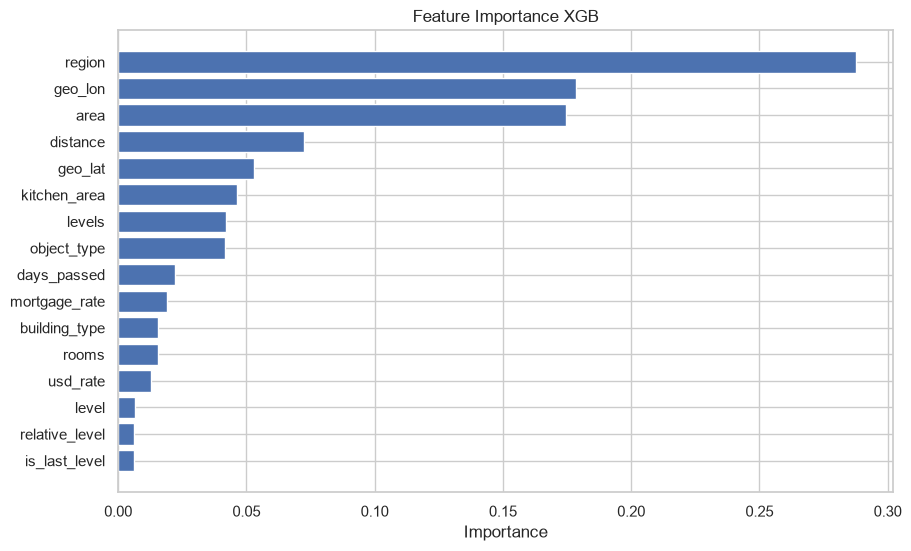

In [58]:
feature_importance = pd.DataFrame({
    "feature": X_train_xgb.columns,
    "importance": xgb_final.feature_importances_,
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.xlabel('Importance')
plt.title('Feature Importance XGB')
plt.gca().invert_yaxis()
plt.show()

Конечный pipeline

In [59]:
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", xgb_final),
])

Сохраняем модель

In [65]:
bundle = {
    "pipeline": pipeline,
    "metadata":{
        "version": "0.1.0",
        "features": X_train.columns.tolist(),
        "threshold": None,
    },
}

joblib.dump(bundle, "cost_model.joblib")

['cost_model.joblib']

### Выводы

В проекте была решена задача регрессии для прогнозирования стоимости квартир.

**Лучшая модель:** XGBoost (R² = 93.71%, MAE = 379 946 руб)

**Наиболее важными признаками оказались**:
- средняя цена в регионе
- расстояние до центра региона
- площадь квартиры и количество комнат
- дата размещения объявления

**Feature engineering:**  
Созданные признаки (region_te, area_to_rooms, kitchen_ratio) улучшили качество всех моделей.